# How long do Canadian immigration applications take?

A walk-through of one snapshot of IRCC's processing-times feed for permanent residence and citizenship
(estimates last updated July 7, 2026; downloaded July 22, 2026). The write-up is in the
[README](README.md). Every chart below is drawn by the same functions as `make_figures.py`.

*Source: Immigration, Refugees and Citizenship Canada, 'Check processing times' data feed on canada.ca,
snapshot 22 July 2026. Reproduced for non-commercial analysis; this is not an official version.*

In [1]:
from pathlib import Path

from ircc_times import analysis, figures, load

SNAPSHOT = Path("data/raw/flpt-en-2026-07-22.json")
feed = load.load_feed(SNAPSHOT)
programs = load.programs_table(feed)
months = load.months_table(feed)
figures.apply_style()

print(feed["default-update"])
print(f"{len(programs)} programs, {len(months):,} rows of program x application month")

{'flpt_lastupdated': 'July 7, 2026', 'flpt_interval': 'monthly'}
28 programs, 3,574 rows of program x application month


## What is in the feed

The file has four sections. Two describe a **new applicant** for each program, and two describe someone who
**already applied** in a given month:

| Section | Example key | Example value |
|---|---|---|
| `current-flpt` | `pgp-roc` | "About 30 months" (estimated wait if you apply now) |
| `total-people` | `pgp-roc` | "About 40,400 people waiting" |
| `wait-times` | `pgp-roc-2025/07` | time left for someone who applied in July 2025 |
| `people-ahead` | `pgp-roc-2025/07` | how many people are ahead of that person |

Codes ending in `-quebec` or `-roc` ("rest of Canada") are the same program split by where the applicant
will live. **There is no country-of-residence field**, so I could not answer my original question about
how much your country changes the wait. The breakdown this feed does have is the month you applied.

Two entries from each section:

In [2]:
{section: dict(list(entries.items())[:2]) for section, entries in feed.items() if section != "default-update"}

{'total-people': {'aip': 'About 12,300 people waiting',
  'caregiver': 'About 37,800 people waiting'},
 'current-flpt': {'aip': 'About 26 months', 'caregiver': 'About 79 months'},
 'people-ahead': {'aip-2016/01': 'Less than 100 people ahead of you',
  'aip-2016/02': 'Less than 100 people ahead of you'},
 'wait-times': {'aip-2016/01': 'We need more time to process your application',
  'aip-2016/02': 'We need more time to process your application'}}

## Turning text into numbers

Every value is display text, so `ircc_times/parse.py` turns it into a number plus a *qualifier*:

* **Unit:** everything is stored in **months**, the unit IRCC uses here. "More than 10 years" becomes
  120 months. (Days and weeks are also accepted, at 365.25 / 12 = 30.44 days per month, because IRCC's
  visa and permit pages use them, but none appear in this file.)
* **Qualifier:** "about", "more than" or "less than" is kept next to the number. "More than 10 years" is a
  *floor*: the real wait is longer, so I never treat 120 as the actual value.
* **Messages:** "We need more time to process your application" and "No data available" become missing
  values (NaN), not zero, so they can't drag an average down.
* **Counts:** "Less than 100 people ahead of you" is read as 100, the highest value it could be.
* Any text that doesn't match a known pattern raises an error instead of quietly becoming NaN.

Every pattern in the time-left column, with the number replaced by N:

In [3]:
(months.assign(pattern=months["months_left_text"].str.replace(r"\d[\d,]*", "N", regex=True))
       .groupby(["pattern", "months_left_qualifier"]).size().rename("rows")
       .sort_values(ascending=False).to_frame())

,,rows
pattern,months_left_qualifier,
We need more time to process your application,need more time,2412
N months left,none,876
More than N years,more than,160
About N month left,about,95
No data available,no data,31


In [4]:
print(programs["wait_text"].str.replace(r"\d[\d,]*", "N", regex=True).value_counts(), "\n")
print(months["people_ahead_qualifier"].value_counts(), "\n")
print(programs["people_waiting_qualifier"].value_counts())

wait_text
About N months       21
More than N years     6
N months              1
Name: count, dtype: int64 

people_ahead_qualifier
about        2726
less than     848
Name: count, dtype: int64 

people_waiting_qualifier
about    28
Name: count, dtype: int64


The result is two tidy tables: one row per program, and one row per program and application month.
Here are the last few months for Federal Skilled Worker:

In [5]:
programs.head(3)

,code,program,family,destination,label,wait_months,wait_qualifier,wait_text,people_waiting,people_waiting_qualifier
0,aip,Atlantic Immigration Program,Economic,NaN,Atlantic Immigration Program,26.0,about,About 26 months,12300.0,about
1,caregiver,Caregivers,Economic,NaN,Caregivers,79.0,about,About 79 months,37800.0,about
2,cec,Canadian Experience Class,Economic,NaN,Canadian Experience Class,6.0,about,About 6 months,61500.0,about


In [6]:
months.loc[months["code"] == "fsw"].tail(6)

,code,applied,months_since_applied,months_left,months_left_qualifier,months_left_text,people_ahead,people_ahead_qualifier
1048,fsw,2026-01-01,6,2.0,none,2 months left,14900.0,about
1049,fsw,2026-02-01,5,2.0,none,2 months left,21100.0,about
1050,fsw,2026-03-01,4,3.0,none,3 months left,26000.0,about
1051,fsw,2026-04-01,3,4.0,none,4 months left,38000.0,about
1052,fsw,2026-05-01,2,5.0,none,5 months left,46900.0,about
1053,fsw,2026-06-01,1,6.0,none,6 months left,55800.0,about


## Checks before the analysis

The analysis relies on three things being true, so `check_feed` stops with an error if any of them fails:

1. **"People ahead" never falls** as the application month gets later. That lets me read it as a running
   total: everyone still waiting who applied in that month or earlier.
2. **For the newest month, "people ahead" equals the total waiting.** The two sections of the feed agree.
3. **Every "more than 10 years" floor is above every ordinary estimate** (the longest is 79 months). So
   floors can still be *ranked* as the longest waits, which keeps the median and rank correlations valid.

In [7]:
analysis.check_feed(programs, months)
print("All three checks passed")

All three checks passed


## Q1. Which application types take longest, and how wide is the spread?

This uses the estimate for a **new applicant** in each of the 28 programs.

In [8]:
(programs.sort_values(["wait_months", "label"], ascending=[False, True])
         [["label", "family", "wait_text", "wait_months", "people_waiting"]]
         .reset_index(drop=True))

,label,family,wait_text,wait_months,people_waiting
0,Dependants of protected persons (Quebec),Refugees and humanitarian,More than 10 years,120.0,22100.0
1,Humanitarian and compassionate (Quebec),Refugees and humanitarian,More than 10 years,120.0,19700.0
2,Humanitarian and compassionate (outside Quebec),Refugees and humanitarian,More than 10 years,120.0,54500.0
3,Protected persons in Canada (Quebec),Refugees and humanitarian,More than 10 years,120.0,40900.0
4,Self-employed persons,Economic,More than 10 years,120.0,8000.0
5,Start-up Visa,Economic,More than 10 years,120.0,47500.0
6,Caregivers,Economic,About 79 months,79.0,37800.0
7,Quebec Business Class,Economic,About 75 months,75.0,3700.0
8,Parents and grandparents (Quebec),Family,About 65 months,65.0,10500.0
9,Privately sponsored refugees (Quebec),Refugees and humanitarian,About 55 months,55.0,2300.0


In [9]:
waits = programs.set_index("label")["wait_months"]
floor = programs.set_index("label")["wait_qualifier"] == analysis.FLOOR
print(f"Shortest: {waits.idxmin()}, {waits.min():.0f} months")
print(f"'More than 10 years': {floor.sum()} programs")
print(f"Median program: {waits.median():.0f} months")
print(f"Two years or more: {(waits >= 24).sum()} of {len(waits)}")

Shortest: Canadian Experience Class, 6 months
'More than 10 years': 6 programs
Median program: 31 months
Two years or more: 17 of 28


The median is safe to quote even with six unknown values, because all six sit above it.
By family (a maximum of 120 means "more than 10 years"):

In [10]:
programs.groupby("family")["wait_months"].agg(["count", "min", "median", "max"])

,count,min,median,max
family,,,,
Citizenship,2,12.0,15.5,19.0
Economic,10,6.0,19.0,120.0
Family,6,17.0,31.0,65.0
Refugees and humanitarian,10,10.0,48.0,120.0


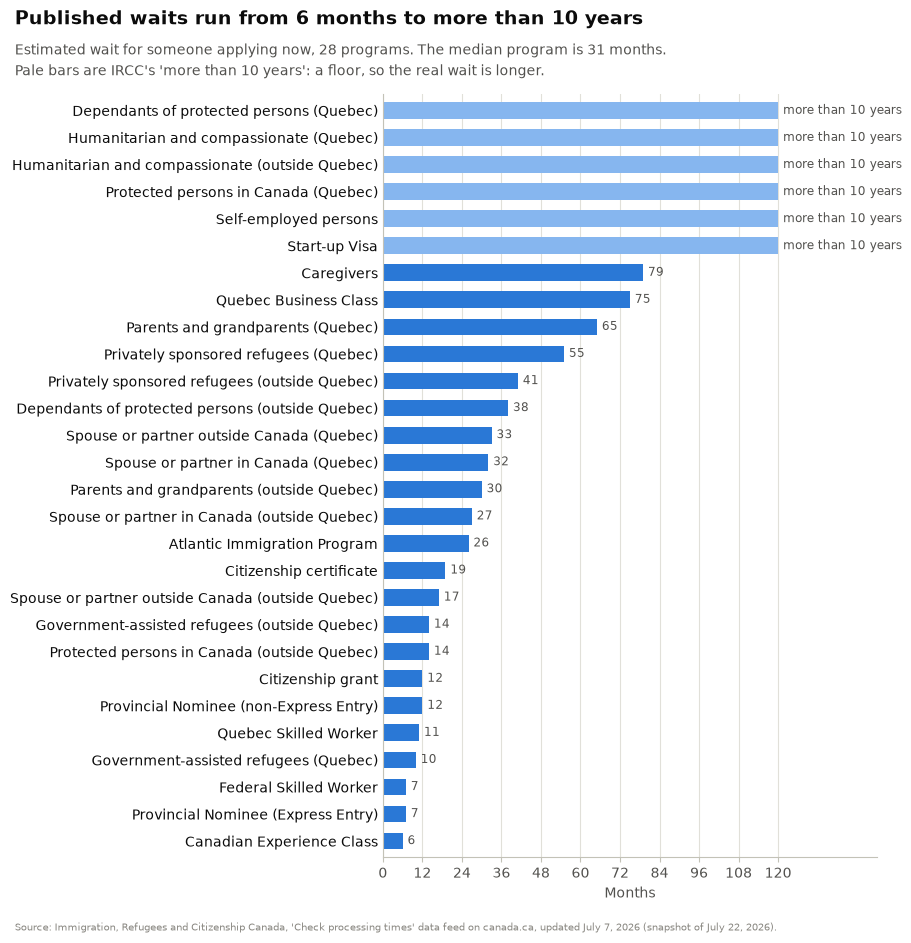

In [11]:
fig = figures.published_waits(programs)

## Q2. How long have the people in each queue already waited?

*(This replaces my question about country of residence, which the feed can't answer.)*

Because "people ahead of you" is a running total, its value for the last month before a cut-off is the
number of people still waiting who applied before that cut-off. In the Federal Skilled Worker rows below,
about 3,500 people are ahead of someone who applied in June 2025, so about 3,500 of the 55,800 people
waiting applied in June 2025 or earlier, more than a year before IRCC's July 2026 update.

In [12]:
fsw = months.loc[months["code"] == "fsw"].set_index("applied")
fsw.loc["2025-04":"2025-09", ["months_since_applied", "people_ahead", "months_left_text"]]

,months_since_applied,people_ahead,months_left_text
applied,,,
2025-04-01,15,2700.0,We need more time to process your application
2025-05-01,14,3400.0,We need more time to process your application
2025-06-01,13,3500.0,We need more time to process your application
2025-07-01,12,3500.0,We need more time to process your application
2025-08-01,11,3500.0,We need more time to process your application
2025-09-01,10,3800.0,About 1 month left


In [13]:
age = analysis.queue_age(months)
labels = programs.set_index("code")["label"]
total = age.to_numpy().sum()
over_1y = age["over 2 years"] + age["1 to 2 years"]
print(f"People waiting in all 28 queues: {total:,.0f}")
print(f"Applied more than 1 year ago:  {over_1y.sum():,.0f} ({over_1y.sum() / total:.1%})")
print(f"Applied more than 2 years ago: {age['over 2 years'].sum():,.0f} ({age['over 2 years'].sum() / total:.1%})")
print(f"Programs where most applied more than a year ago: {(over_1y / age.sum(axis=1) > 0.5).sum()} of {len(age)}")

percent = age.div(age.sum(axis=1), axis=0).mul(100).round(1).add_prefix("% ")
(percent.assign(**{"% more than 1 year": (over_1y / age.sum(axis=1)).mul(100).round(1),
                   "people waiting": age.sum(axis=1)})
        .rename(index=labels).rename_axis("program").sort_values("% more than 1 year", ascending=False))

People waiting in all 28 queues: 1,374,100
Applied more than 1 year ago:  544,300 (39.6%)
Applied more than 2 years ago: 272,600 (19.8%)
Programs where most applied more than a year ago: 18 of 28


,% over 2 years,% 1 to 2 years,% 1 year or less,% more than 1 year,people waiting
program,,,,,
Caregivers,68.3,31.7,0.0,100.0,37800.0
Self-employed persons,100.0,0.0,0.0,100.0,8000.0
Quebec Business Class,89.2,5.4,5.4,94.6,3700.0
Privately sponsored refugees (outside Quebec),54.8,32.5,12.8,87.2,73600.0
Start-up Visa,59.4,27.6,13.1,86.9,47500.0
Parents and grandparents (Quebec),53.3,30.5,16.2,83.8,10500.0
Humanitarian and compassionate (Quebec),51.3,23.9,24.9,75.1,19700.0
Dependants of protected persons (Quebec),49.8,24.9,25.3,74.7,22100.0
Privately sponsored refugees (Quebec),47.8,21.7,30.4,69.6,2300.0


The counts in the feed come in hundreds, so the shares for very small queues are rough
(Government-assisted refugees in Quebec has about 300 people waiting, so each 100 people is a third of it).

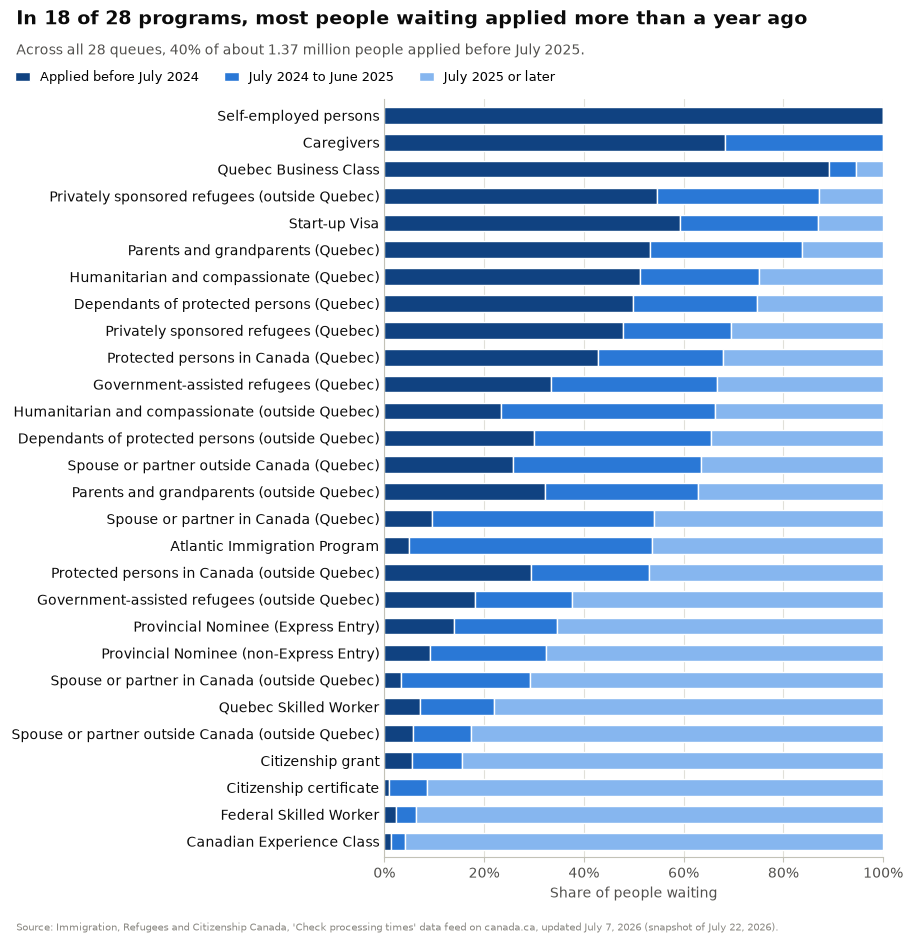

In [14]:
fig = figures.queue_age_chart(age, labels, load.last_updated(feed))

## Q3. Is a bigger queue associated with a longer published time?

There are two ways to ask this, and they give opposite answers.

**Inside one program**, across application months: the more people ahead of you, the more time IRCC says
is left. IRCC says the estimates are based on the applications it already has and the number it expects to
process each month, so this is a check on my reading of the data rather than a discovery.
I use Spearman's rank correlation, which only asks whether the two go up together.

In [15]:
within = analysis.within_program_rho(months)
within.describe().round(3)

count    28.000
mean      0.983
std       0.033
min       0.840
25%       0.984
50%       0.994
75%       0.999
max       1.000
dtype: float64

**Across programs**: does a program with a bigger queue publish a longer wait? Spearman's correlation
works with ranks, so the six "more than 10 years" programs can be included as tied for longest, which
check 3 above makes safe. As a sensitivity check I also leave them out.

In [16]:
across = analysis.queue_vs_wait(programs)
exact = programs[programs["wait_qualifier"] != analysis.FLOOR]
without_floors = analysis.queue_vs_wait(exact)
print(f"All {len(programs)} programs:    rho = {across.statistic:.2f}, p = {across.pvalue:.2f}")
print(f"Without the floors ({len(exact)}): rho = {without_floors.statistic:.2f}, p = {without_floors.pvalue:.2f}")

All 28 programs:    rho = -0.24, p = 0.21
Without the floors (22): rho = -0.26, p = 0.24


Across programs the correlation is weak and slightly negative, and a p-value around 0.2 means a pattern
this size could easily appear by chance. These 28 programs aren't a random sample and this is one month,
so I read it as "no clear relationship", not as evidence either way.

Why doesn't queue size predict the wait? Dividing the queue by the wait gives roughly the number of people
per month IRCC expects to process in that program. That pace differs enormously between programs (for a
"more than 10 years" program it's an upper bound):

In [17]:
(programs.assign(implied_people_per_month=(programs["people_waiting"] / programs["wait_months"]).round())
         [["label", "people_waiting", "wait_months", "wait_qualifier", "implied_people_per_month"]]
         .sort_values("implied_people_per_month").reset_index(drop=True))

,label,people_waiting,wait_months,wait_qualifier,implied_people_per_month
0,Government-assisted refugees (Quebec),300.0,10.0,about,30.0
1,Privately sponsored refugees (Quebec),2300.0,55.0,about,42.0
2,Quebec Business Class,3700.0,75.0,about,49.0
3,Self-employed persons,8000.0,120.0,more than,67.0
4,Parents and grandparents (Quebec),10500.0,65.0,about,162.0
5,Humanitarian and compassionate (Quebec),19700.0,120.0,more than,164.0
6,Dependants of protected persons (Quebec),22100.0,120.0,more than,184.0
7,Protected persons in Canada (Quebec),40900.0,120.0,more than,341.0
8,Start-up Visa,47500.0,120.0,more than,396.0
9,Spouse or partner in Canada (Quebec),13700.0,32.0,about,428.0


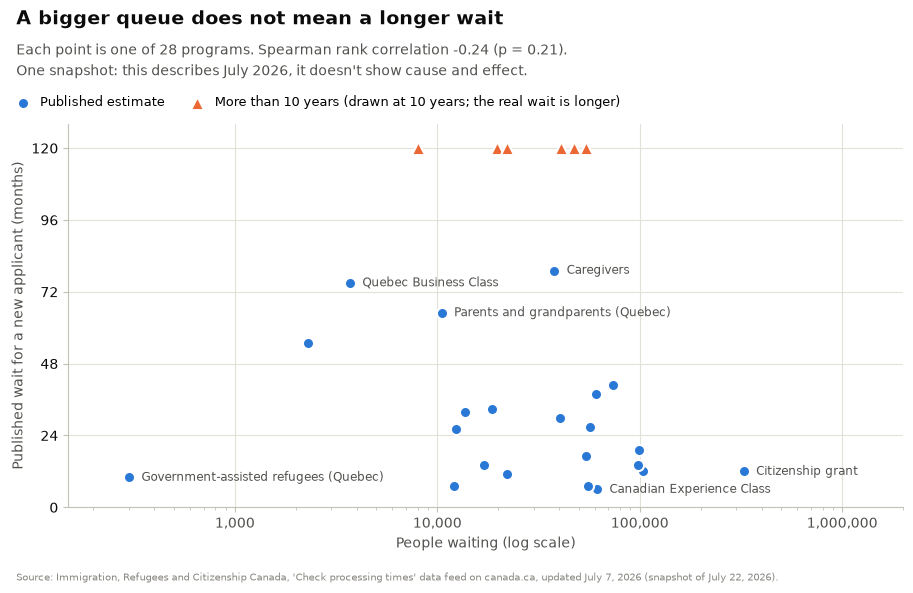

In [18]:
fig = figures.queue_vs_wait_chart(programs, across.statistic, across.pvalue)

## Q4. Are there differences between Quebec and the rest of Canada?

IRCC publishes separate times for eight programs depending on whether the applicant will live in Quebec.
Its processing-times page explains that under the Canada–Quebec Accord the Government of Quebec also has
to process these applications. Where one side is "more than 10 years", the gap is a minimum; where both
sides are, they can't be compared.

In [19]:
pairs = analysis.quebec_pairs(programs)
pairs

,quebec,outside,quebec_floor,outside_floor,difference,longer
program,,,,,,
Protected persons in Canada,120.0,14.0,True,False,106.0,Quebec
Dependants of protected persons,120.0,38.0,True,False,82.0,Quebec
Parents and grandparents,65.0,30.0,False,False,35.0,Quebec
Spouse or partner outside Canada,33.0,17.0,False,False,16.0,Quebec
Privately sponsored refugees,55.0,41.0,False,False,14.0,Quebec
Spouse or partner in Canada,32.0,27.0,False,False,5.0,Quebec
Government-assisted refugees,10.0,14.0,False,False,-4.0,Outside Quebec
Humanitarian and compassionate,120.0,120.0,True,True,NaN,Can't tell


The Quebec queues are also smaller in every pair, which is another sign that queue size alone doesn't
set the wait:

In [20]:
(programs.dropna(subset=["destination"])
         .pivot(index="program", columns="destination", values="people_waiting")
         .assign(quebec_smaller=lambda t: t["Quebec"] < t["outside Quebec"]))

destination,Quebec,outside Quebec,quebec_smaller
program,,,
Dependants of protected persons,22100.0,60800.0,True
Government-assisted refugees,300.0,17000.0,True
Humanitarian and compassionate,19700.0,54500.0,True
Parents and grandparents,10500.0,40400.0,True
Privately sponsored refugees,2300.0,73600.0,True
Protected persons in Canada,40900.0,98300.0,True
Spouse or partner in Canada,13700.0,56900.0,True
Spouse or partner outside Canada,18600.0,54100.0,True


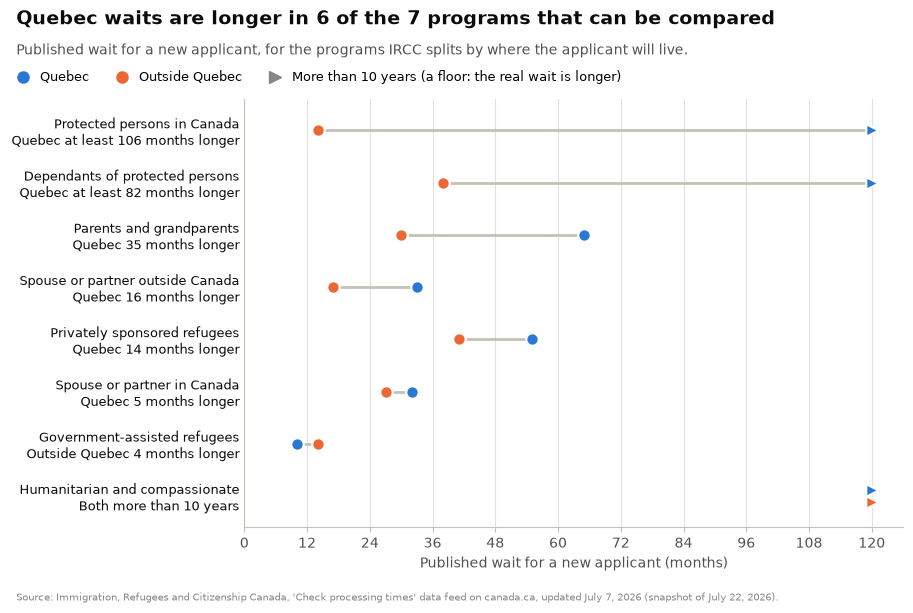

In [21]:
fig = figures.quebec_chart(pairs)

## Data limits: what the tool tells people who already applied

Most rows in `wait-times` don't contain a time. Counting rows makes that look like a huge gap, but rows
aren't people. Weighting each month by the number of people in it (the step in the running total of
"people ahead") gives a very different picture.

In [22]:
mix = analysis.answer_mix(months)
mix.assign(**{"% of rows": (mix["rows"] / mix["rows"].sum()).mul(100).round(1),
              "% of people": (mix["people"] / mix["people"].sum()).mul(100).round(1)})

,rows,people,% of rows,% of people
answer,,,,
Time left given,971,1174300.0,27.2,85.5
More than 10 years,160,110100.0,4.5,8.0
We need more time to process your application,2412,89700.0,67.5,6.5
No data available,31,0.0,0.9,0.0


In [23]:
message = months["months_left_qualifier"] == "need more time"
people_in_month = analysis.people_per_month(months)
print(f"Rows with the message: {message.sum():,}")
print(f"  for months more than two years old: {(months.loc[message, 'months_since_applied'] > 24).mean():.1%}")
print(f"  holding 100 people or fewer:        {(people_in_month[message] <= 100).mean():.1%}")

Rows with the message: 2,412
  for months more than two years old: 96.6%
  holding 100 people or fewer:        95.0%


Reading "Less than 100" as 100 can only *overstate* the number of people behind the message, so the
true share is, if anything, a little lower.

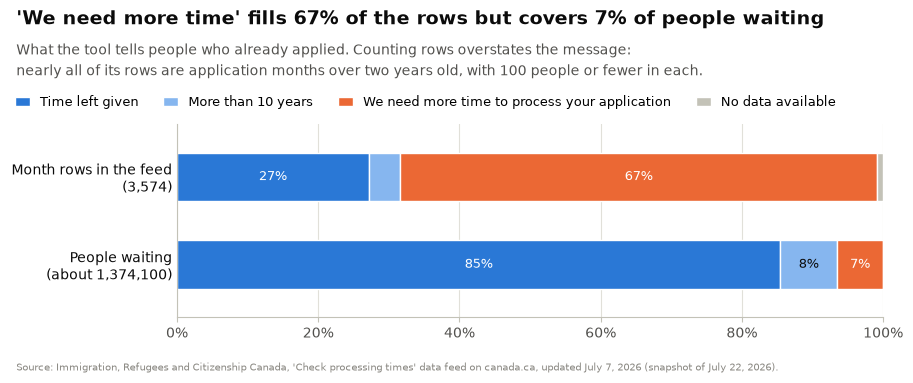

In [24]:
fig = figures.answer_mix_chart(mix)

## Limits

* **One snapshot.** These are IRCC's estimates as of July 2026, not a trend, and not anyone's actual
  processing time. IRCC says its times are not a maximum or a guarantee.
* **Rounded inputs.** Every count is a multiple of 100 and every time is a whole number of months.
* **Floors.** Six programs are only "more than 10 years", so their real values are unknown; I rank them
  but never average them.
* **Correlation isn't cause**, and 28 programs is a small set.

The next step is to save this feed every month and compare snapshots, which would turn these one-off
descriptions into trends.